# Notebook 01 — Black–Scholes Derivation, SymPy Verification & Greeks

**Goal:** Derive the Black–Scholes formula step by step (Geometric Brownian Motion $\to$ Itô's Lemma $\to$ Delta-Hedged PDE & Risk-Neutral Pricing), verify the algebra symbolically with `sympy`, and inspect the Greeks across maturities.

---

## Step 1: The Stock Model and Itô's Lemma

We model the stock price $S_t$ under Geometric Brownian Motion (GBM):
$$dS_t = \mu S_t \, dt + \sigma S_t \, dW_t$$
where $\mu$ is the real-world expected return, $\sigma$ is annualized volatility, and $W_t$ is a standard Brownian motion with quadratic variation $(dW_t)^2 = dt$.

Applying **Itô's Lemma** to $f(S) = \ln S$ with $f'(S) = 1/S$ and $f''(S) = -1/S^2$:
$$d(\ln S_t) = \frac{1}{S_t} dS_t + \frac{1}{2}\left(-\frac{1}{S_t^2}\right)(dS_t)^2 = \left(\mu - \frac{1}{2}\sigma^2\right)dt + \sigma \, dW_t$$

Because $(dW_t)^2 = dt$, the second-order Taylor term does not vanish. Integrating from $0$ to $T$ gives the exact log-normal terminal stock price:
$$S_T = S_0 \exp\left[\left(\mu - \frac{1}{2}\sigma^2\right)T + \sigma W_T\right], \quad W_T \sim \mathcal{N}(0, T)$$

## Step 2: The Black–Scholes PDE via Delta Hedging

Let $V(S, t)$ be the value of a European option on a stock paying a continuous dividend yield $q$. We construct a self-financing portfolio $\Pi = V - \Delta S$ (long 1 option, short $\Delta$ shares). Over $dt$, the short position must also pay the dividend $q \Delta S \, dt$:
$$d\Pi = dV - \Delta \, dS - q \Delta S \, dt$$

Expanding $dV$ by Itô's Lemma:
$$d\Pi = \left(V_t + \frac{1}{2}\sigma^2 S^2 V_{SS} - q \Delta S\right)dt + (V_S - \Delta)dS$$

Choosing **$\Delta = V_S = \frac{\partial V}{\partial S}$** eliminates the random $dW_t$ term completely:
$$d\Pi = \left(V_t + \frac{1}{2}\sigma^2 S^2 V_{SS} - q S V_S\right)dt$$

By no-arbitrage, a riskless portfolio must grow at the risk-free rate $r$, so $d\Pi = r \Pi \, dt = r(V - S V_S)dt$. Equating the two expressions gives the **Black–Scholes PDE**:
$$V_t + \frac{1}{2}\sigma^2 S^2 V_{SS} + (r - q)S V_S - rV = 0, \quad V(S, T) = \text{payoff}(S)$$

**Key Insight:** The stock's real-world drift $\mu$ has vanished. Option prices depend only on the risk-neutral drift $(r - q)$ and volatility $\sigma$.

## Step 3: Risk-Neutral Expectation & Feynman–Kac Link

By the **Feynman–Kac theorem**, the solution to the Black–Scholes PDE with terminal condition $V(S, T) = \text{payoff}(S_T)$ equals the discounted expectation of the payoff under the risk-neutral measure $\mathbb{Q}$, where the drift of $S_t$ is $(r - q)$:
$$S_T = S_0 \exp\left[\left(r - q - \frac{1}{2}\sigma^2\right)T + \sigma\sqrt{T} Z\right], \quad Z \sim \mathcal{N}(0, 1)$$

For a European call, $C = e^{-rT}\mathbb{E}^{\mathbb{Q}}[(S_T - K)^+] = e^{-rT}\mathbb{E}^{\mathbb{Q}}[S_T \mathbf{1}_{\{S_T > K\}}] - K e^{-rT}\mathbb{Q}(S_T > K)$.
* $\mathbb{Q}(S_T > K) = N(d_2)$
* Completing the square in the Gaussian integral via $\mathbb{E}[e^{aZ}\mathbf{1}_{\{Z > c\}}] = e^{a^2/2}N(a - c)$ gives $\mathbb{E}^{\mathbb{Q}}[S_T \mathbf{1}_{\{S_T > K\}}] = S_0 e^{(r-q)T} N(d_1)$.

Combining both terms yields the closed-form formulas:
$$d_1 = \frac{\ln(S/K) + (r - q + \frac{1}{2}\sigma^2)T}{\sigma\sqrt{T}}, \quad d_2 = d_1 - \sigma\sqrt{T}$$
$$\text{Call} = S e^{-qT} N(d_1) - K e^{-rT} N(d_2), \quad \text{Put} = K e^{-rT} N(-d_2) - S e^{-qT} N(-d_1)$$
$$\text{Put–Call Parity:} \quad \text{Call} - \text{Put} = S e^{-qT} - K e^{-rT}$$

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from src.black_scholes import bs_price, bs_greeks

# 1. Define symbolic variables (T = time to maturity)
S, K, T, r, q, sig = sp.symbols("S K T r q sigma", positive=True)
N = lambda x: sp.erf(x / sp.sqrt(2)) / 2 + sp.Rational(1, 2)
phi = lambda x: sp.exp(-x**2 / 2) / sp.sqrt(2 * sp.pi)

d1 = (sp.log(S / K) + (r - q + sig**2 / 2) * T) / (sig * sp.sqrt(T))
d2 = d1 - sig * sp.sqrt(T)

# 2. Verify the Greek helper lemma: S * exp(-qT) * phi(d1) == K * exp(-rT) * phi(d2)
lemma_diff = sp.simplify(S * sp.exp(-q * T) * phi(d1) - K * sp.exp(-r * T) * phi(d2))
print(f"Greek Identity Symbolic Difference: {lemma_diff}")

# 3. Verify the Black-Scholes PDE residual
C = S * sp.exp(-q * T) * N(d1) - K * sp.exp(-r * T) * N(d2)
pde_residual = (
    -sp.diff(C, T)
    + sp.Rational(1, 2) * sig**2 * S**2 * sp.diff(C, S, 2)
    + (r - q) * S * sp.diff(C, S)
    - r * C
)

vals = {S: 100, K: 105, T: 0.5, r: 0.03, q: 0.01, sig: 0.20}
numeric_resid = float(pde_residual.subs(vals))
print(f"PDE Residual at Reference Parameters: {numeric_resid:.2e}")
assert abs(numeric_resid) < 1e-14

Greek Identity Symbolic Difference: 0
PDE Residual at Reference Parameters: -4.64e-15


In [2]:
# Differentiate Call price symbolically with SymPy and compare with src/black_scholes.py
sym_delta = sp.diff(C, S)
sym_gamma = sp.diff(C, S, 2)
sym_vega = sp.diff(C, sig)

analytic_greeks = bs_greeks(S=100.0, K=105.0, T=0.5, r=0.03, sigma=0.20, q=0.01, kind="call")

print(" Greek | SymPy Value | bs_greeks() | Abs Diff")
print("-" * 50)
for name, sym_expr in [("delta", sym_delta), ("gamma", sym_gamma), ("vega", sym_vega)]:
    s_val = float(sym_expr.subs(vals))
    a_val = analytic_greeks[name]
    print(f" {name:<5} | {s_val:11.7f} | {a_val:11.7f} | {abs(s_val - a_val):.2e}")
    assert abs(s_val - a_val) < 1e-12

 Greek | SymPy Value | bs_greeks() | Abs Diff
--------------------------------------------------
 delta |   0.4172505 |   0.4172505 | 5.55e-17
 gamma |   0.0274931 |   0.0274931 | 1.39e-17
 vega  |  27.4931319 |  27.4931319 | 0.00e+00


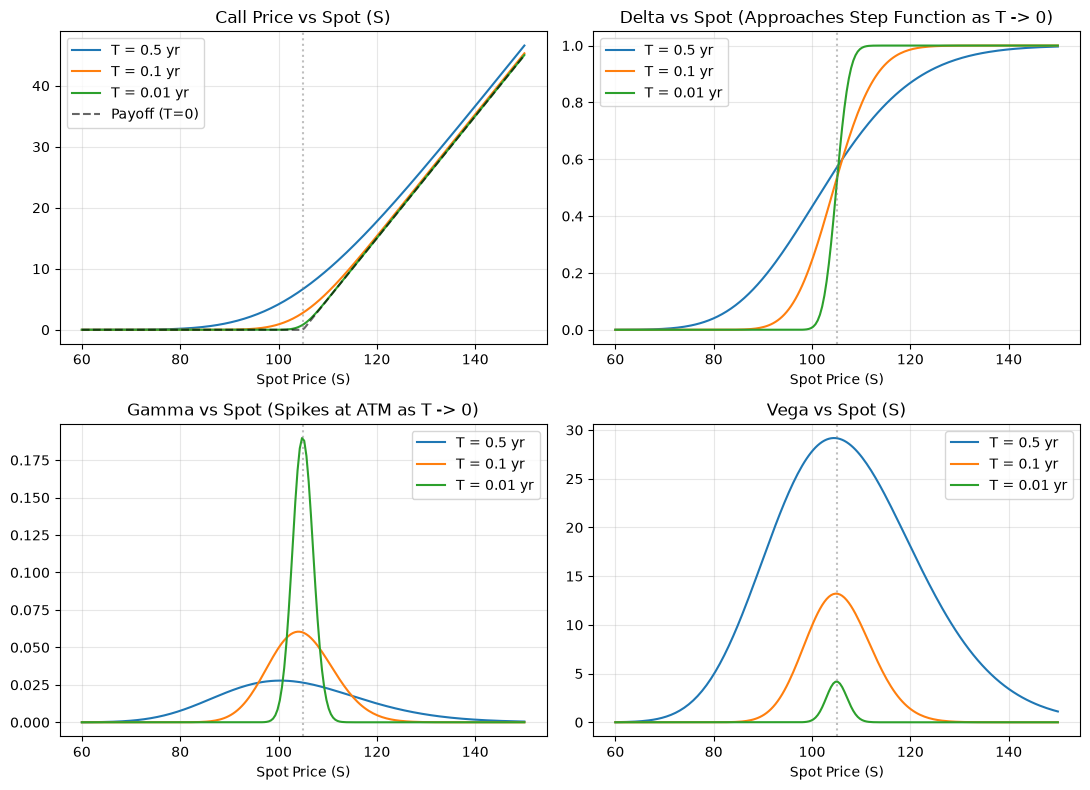

In [3]:
# Plot Call Price, Delta, Gamma, and Vega vs Spot S across maturities T
spots = np.linspace(60, 150, 200)
K_ref, r_ref, sig_ref, q_ref = 105.0, 0.03, 0.20, 0.0
maturities = [0.5, 0.1, 0.01]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for T_val in maturities:
    label = f"T = {T_val} yr"
    prices = [bs_price(s, K_ref, T_val, r_ref, sig_ref, q_ref, "call") for s in spots]
    g_list = [bs_greeks(s, K_ref, T_val, r_ref, sig_ref, q_ref, "call") for s in spots]

    axes[0, 0].plot(spots, prices, label=label)
    axes[0, 1].plot(spots, [g["delta"] for g in g_list], label=label)
    axes[1, 0].plot(spots, [g["gamma"] for g in g_list], label=label)
    axes[1, 1].plot(spots, [g["vega"] for g in g_list], label=label)

axes[0, 0].plot(spots, np.maximum(spots - K_ref, 0), "k--", alpha=0.6, label="Payoff (T=0)")
axes[0, 0].set_title("Call Price vs Spot (S)")
axes[0, 1].set_title("Delta vs Spot (Approaches Step Function as T -> 0)")
axes[1, 0].set_title("Gamma vs Spot (Spikes at ATM as T -> 0)")
axes[1, 1].set_title("Vega vs Spot (S)")

for ax in axes.flat:
    ax.axvline(K_ref, color="gray", linestyle=":", alpha=0.5)
    ax.set_xlabel("Spot Price (S)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
out_path = Path.cwd().parent / "report" / "figures" / "01_bs_greeks.png"
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, dpi=200)
plt.show()